# Data Scientist Case Study: Feature Engineering and Training

This notebook consolidates the feature engineering developed during the EDA (`Data Scientist Case Study.ipynb`, sections 1–2)
into **reusable functions**. A single call, `engineer_features(raw)`, turns the raw parquet into a model-ready table and
returns the fitted parameters, so the identical transformation can be applied to new data later.

## 1. Feature engineering

### 1.1 What the pipeline does and why

| # | Step | Source field(s) | Output columns | Why |
|---|---|---|---|---|
| 1 | **Index reset** | – | – | The parquet index restarts per state (2.3M duplicate labels), which silently breaks joins. |
| 2 | **Placeholder flags → missing** | `search_conducted`, `contraband_found`, `drugs_related_stop`, `out_of_state` | `*_clean` | Some states fill these with a constant (e.g. 100% of NV stops "searched"), and MT's `contraband_found` is a copy of `search_conducted`. These are defaults, not observations. |
| 3 | **Time** | `stop_date`, `stop_time` | `year`, `month`, `day_of_week`, `is_weekend`, `hour`, `hour_sin/cos`, `is_night` | Arrests concentrate between 00:00 and 04:00 and on weekends. Cyclical encoding keeps 23:00 next to 01:00. |
| 4 | **Violation (multi-label)** | `violation` | 15 × `viol_*`, `n_violations` | WI/MT list several violations per stop (`"Paperwork,Speeding"`, 1,500+ combinations). |
| 5 | **Charges hidden in raw violation text** | `violation_raw` | 9 × `vraw_*` | The standardized "Other" bucket hides warrant/FTA (98% arrest in NV), drug and alcohol charges. |
| 6 | **Search basis** | `search_type_raw` (free text, multi-valued, state vocabularies) | 11 × `search_*`, `search_basis_known`, `n_search_bases` | Maps "CONSENT SEARCH CONDUCTED", "Consent Search-Rsnbl Suspicion", "Terry Frisk"… onto common legal bases. |
| 7 | **Stop outcome** | `stop_outcome` (12 state-specific labels), MT `stop_outcome_raw` (multi-valued) | `outcome_std`, 8 × `outcome_raw_*` | Standardized severity scale. **These columns are the target in another form** and are kept only for diagnostics. |
| 8 | **Location** | `fine_grained_location` (free text in MT/VT; semi-structured `"<dir> <hwy> <street>"` in WI) | `road_class`, `has_milepost`, `is_intersection`, `is_ramp_exit`, `interstate_id` | Road type and corridor carry state-specific risk (MT I-90 4.1% vs I-15 1.0%; WI local streets 2.2×). |
| 9 | **Geography & vehicle** | `county_name`/`district`, `police_department`, `vehicle_year`/WI `vehicle_type` | `geo_unit`, normalized `police_department`, `vehicle_age` | RI has zones instead of counties. RI department codes mix `"500"`/`"500.0"`. WI hides the model year in `vehicle_type`. |
| 10 | **Outlier-period removal** | `state`, `stop_date`, `is_arrested` | `period_status`, `period_keep` | Removes recording-artifact periods (NV pre-mid-2014 with no recorded arrests, MT/RI/WI ramp-up months), with a preference for the most recent years. |

### 1.2 Outlier-period rule (step 10)
For each state, monthly arrest rates are scored against a **recent reference window** (the latest 3 calendar years):
`z = (rate − median_ref) / (1.4826 · MAD_ref)`.
* A month is *bad* if `|z| > 3.5` or it has fewer than 500 stops.
* A run of **≥ 3 consecutive bad months** is a structural break. Everything up to the **latest** break is dropped, so the recent stable window is kept.
* **Isolated** bad months inside the kept window are dropped by default (`drop_isolated=True`). Stops with no date are dropped.
* Months *after* the fitted range (new data) are kept. Months before it, or never seen, are dropped.

### 1.3 Fit / apply design
`engineer_features(raw)` **fits** two data-dependent pieces: which (state, flag) pairs are placeholders, and the monthly keep/drop table.
It returns them in `params`. Calling `engineer_features(new_raw, params=params)` **re-uses** them, so a small new batch is
never judged against itself. Every other step is a deterministic rule (regex or mapping) that needs no fitting.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

raw = pd.read_parquet('open_policing_project.parquet')
print(f'{len(raw):,} rows x {raw.shape[1]} columns')

3,383,056 rows x 39 columns


### 1.4 Rule definitions
All regexes and mappings live in one place so they can be reviewed and extended.

In [2]:
PLACEHOLDER_BOOL_COLS = ['search_conducted', 'contraband_found', 'drugs_related_stop', 'out_of_state']

VIOLATION_CATEGORIES = ['Cell phone', 'DUI', 'Equipment', 'License', 'Lights', 'Moving violation', 'Other',
                        'Other (non-mapped)', 'Paperwork', 'Registration/plates', 'Safe movement', 'Seat belt',
                        'Speeding', 'Stop sign/light', 'Truck']

# keyword flags on violation_raw; several are charges discovered *during* the stop
VRAW_FLAGS = {
    'warrant_fta':       r'\bFTA\b|FAILURE TO APPEAR|WARRANT',
    'drugs':             r'DRUG|COCAINE|MARIJUANA|NARCOTIC|CONTROLLED SUBSTANCE|PARAPHERNALIA|\bMETH|HEROIN|\bTHC\b',
    'alcohol_dui':       r'\bDUI\b|\bOWI\b|INTOXICA|UNDER THE INFLUENCE|ALCOHOL|LIQUOR|OPEN CONT|IMPLIED CONSENT|\bPAC\b|\bBAC\b',
    'license_suspended': r'SUSPEND|REVOK|\bOAR\b|\bOAS\b|CANCEL',
    'no_insurance':      r'INSURANCE',
    'evade_resist':      r'ELUD|\bFLEE|RESIST|OBSTRUCT(?:ING)? (?:AN )?OFFICER|FALSE (?:INFO|NAME)|DUTY TO GIVE',
    'weapon':            r'WEAPON|FIREARM|\bGUN\b|KNIFE',
    'theft_stolen':      r'THEFT|STOLEN',
    'reckless':          r'RECKLESS|CARELESS',
}

# legal basis for a search, across the states' vocabularies (applied to upper-cased search_type_raw)
SEARCH_BASES = {
    'consent':              r'(?<!OFFICER )CONSENT',
    'probable_cause':       r'PROBABLE CAUSE',
    'reasonable_suspicion': r'REASONABLE SUSPICION|RSNBL SUSPICION',
    'warrant':              r'WARRANT',
    'incident_to_arrest':   r'INCIDENT TO ARREST',
    'inventory_tow':        r'INVENTORY|/TOW',
    'frisk':                r'FRISK',
    'plain_view':           r'PLAIN VIEW',
    'odor':                 r'ODOR',
    'parole_probation':     r'PROBATION|PAROLE',
    'exigent':              r'EXIGENT',
}

OUTCOME_MAP = {
    'Arrest': 'arrest', 'Arrest Driver': 'arrest', 'Arrest Passenger': 'arrest', 'Arrest for Violation': 'arrest',
    'Warrant Arrest': 'arrest', 'Citation': 'citation', 'Written Warning': 'warning', 'Warning': 'warning',
    'Verbal Warning': 'warning', 'Faulty Equipment Notice': 'warning', 'No Action': 'no action', 'N/D': 'unknown',
}
OUTCOME_ORDER = ['arrest', 'citation', 'warning', 'no action', 'unknown']
# MT stop_outcome_raw tokens (multi-valued, comma separated)
OUTCOME_RAW_TOKENS = {
    'misdemeanor_arrest': 'MISDEMEANOR ARREST', 'felony_arrest': 'FELONY ARREST', 'infraction_arrest': 'INFFRACTION ARREST',
    'citation': 'TRAFFIC CITATION', 'warning': 'WARNING', 'equipment_notice': 'FAULTY EQUIPMENT NOTICE',
    'no_enforcement': 'NO ENFORCEMENT ACTION', 'jurisdictional': 'NONE - JURISDICTIONAL ISSUE',
}

# road classification for free-text locations (MT, VT, and WI rows without a highway number); first match wins
ROAD_RULES = [
    ('interstate',    r'\b(?:I|IH|INTERSTATE)\s?-?\s?\d{2,3}|\bI\d{2,3}[NSEW]?\b'),
    ('us_highway',    r'\bUSH\s?\d|\bUS\s?-?\s?(?:HWY|HIGHWAY|RT|RTE|ROUTE)?\s?-?\s?\d|\bU\.S\.'),
    ('state_highway', r'\bSTH\s?\d|\b(?:MT|VT|SR|S|STATE)\s?-?\s?(?:HWY|HIGHWAY|RT|RTE|ROUTE)?\s?-?\s?\d'
                      r'|\b(?:HWY|HIGHWAY|RT|RTE|ROUTE)\s?-?\s?\d|^\d{1,3}\s+MM'),
    ('county_road',   r'\bCOUNTY\b|\bCTH\b|\bCR\s?-?\s?\d'),
    ('local_street',  r'\b(?:ST|STREET|AVE|AVENUE|RD|ROAD|LN|LANE|DR|DRIVE|BLVD|WAY|CT|PL|PKWY|TRL|TRAIL|HL|HILL|HWY)\b'),
]
ROAD_CLASSES = [c for c, _ in ROAD_RULES] + ['unclassified']
# WI "<dir> <hwy> <rest>": the highway number identifies the road class
WI_INTERSTATES = {39, 43, 90, 94, 535, 794, 894}
WI_US_HWYS = {2, 8, 10, 12, 14, 18, 41, 45, 51, 53, 61, 63, 141, 151}

### 1.5 Feature functions
Each function takes a DataFrame and returns it with new columns added. The functions are composed by `engineer_features` (§1.6).

In [3]:
def _slug(s):
    return re.sub(r'\W+', '_', s.lower()).strip('_')


# --- step 2: placeholder booleans -------------------------------------------------------------------------------
def fit_placeholder_flags(df):
    # (state x flag) -> True where the flag carries no information in that state
    rates = df.groupby('state')[PLACEHOLDER_BOOL_COLS].mean()
    placeholder = rates.isin([0.0, 1.0])
    # a flag that is an exact copy of search_conducted (MT contraband_found) is not an observation either
    copy = df['contraband_found'].eq(df['search_conducted']).groupby(df['state']).all()
    placeholder['contraband_found'] |= copy & (rates['search_conducted'] > 0)
    return placeholder


def clean_placeholder_flags(df, placeholder):
    for c in PLACEHOLDER_BOOL_COLS:
        mask = df['state'].map(placeholder[c]).fillna(False).astype(bool)
        df[c + '_clean'] = df[c].astype('boolean').mask(mask)
    return df


# --- step 3: time ------------------------------------------------------------------------------------------------
def add_time_features(df):
    df['stop_date'] = pd.to_datetime(df['stop_date'])
    # nullable Int64 so dtypes do not depend on whether a batch happens to contain missing values
    df['year'] = df['stop_date'].dt.year.astype('Int64')
    df['month'] = df['stop_date'].dt.month.astype('Int64')
    df['day_of_week'] = df['stop_date'].dt.day_name().str[:3]
    df['is_weekend'] = df['stop_date'].dt.day_of_week.ge(5).astype('boolean').mask(df['stop_date'].isna())
    hour = pd.to_numeric(df['stop_time'].str[:2], errors='coerce').astype('Int64')
    df['hour'] = hour
    df['hour_sin'] = np.sin(2 * np.pi * hour.astype('float64') / 24)
    df['hour_cos'] = np.cos(2 * np.pi * hour.astype('float64') / 24)
    df['is_night'] = (hour.ge(22) | hour.lt(4)).astype('boolean').mask(hour.isna())
    df['driver_age'] = df['driver_age'].round()            # one stray 22.5
    return df


# --- step 4: standardized violation, multi-label -------------------------------------------------------------------
def add_violation_features(df):
    dummies = (df['violation'].str.get_dummies(sep=',').astype(bool)
                 .reindex(columns=VIOLATION_CATEGORIES, fill_value=False))
    dummies.columns = ['viol_' + _slug(c) for c in VIOLATION_CATEGORIES]
    df[dummies.columns] = dummies
    df['n_violations'] = dummies.sum(axis=1)
    return df


# --- step 5: charges in violation_raw --------------------------------------------------------------------------------
def add_violation_raw_flags(df):
    text = df['violation_raw'].str.upper()
    for k, pat in VRAW_FLAGS.items():
        df['vraw_' + k] = text.str.contains(pat, regex=True).fillna(False).astype(bool)
    return df


# --- step 6: search basis --------------------------------------------------------------------------------------------
def add_search_basis_features(df):
    text = df['search_type_raw'].str.upper().where(df['search_type_raw'].ne('No Search Conducted'))
    for k, pat in SEARCH_BASES.items():
        df['search_' + k] = text.str.contains(pat, regex=True).fillna(False).astype(bool)
    df['search_basis_known'] = text.notna()
    df['n_search_bases'] = df[['search_' + k for k in SEARCH_BASES]].sum(axis=1)
    return df


# --- step 7: stop outcome (diagnostic only: leaks the target) -------------------------------------------------------------
def add_outcome_features(df):
    df['outcome_std'] = pd.Categorical(df['stop_outcome'].map(OUTCOME_MAP).fillna('unknown'), OUTCOME_ORDER, ordered=True)
    text = df['stop_outcome_raw'].str.upper()
    for k, tok in OUTCOME_RAW_TOKENS.items():
        pattern = r'(?:^|,)' + re.escape(tok) + r'(?:,|$)'          # whole comma-separated token
        df['outcome_raw_' + k] = text.str.contains(pattern, regex=True).fillna(False).astype(bool)
    return df


# --- step 8: fine_grained_location -----------------------------------------------------------------------------------------
def add_location_features(df):
    loc = df['fine_grained_location'].str.upper().str.strip()
    loc = loc.mask(loc.isin(['', 'NA', 'NA NA NA']))

    # generic keyword rules
    road = pd.Series(np.select([loc.str.contains(p, regex=True).fillna(False).astype(bool) for _, p in ROAD_RULES],
                               [c for c, _ in ROAD_RULES], default='unclassified'), index=df.index)

    # WI: "<dir> <hwy> <rest>"; fall back to the keyword rules when the highway field is NA
    wi = df['state'].eq('WI') & loc.notna()
    parts = loc[wi].str.extract(r'^(?P<dir>N|S|E|W|NA)\s+(?P<hwy>\S+)\s*(?P<rest>.*)$')
    hwy_num = pd.to_numeric(parts['hwy'], errors='coerce')
    county_letters = (parts['hwy'].str.fullmatch(r'[A-Z]{1,2}') & parts['hwy'].ne('NA')).fillna(False).astype(bool)
    wi_class = np.select([hwy_num.isin(WI_INTERSTATES), hwy_num.isin(WI_US_HWYS), hwy_num.notna(), county_letters],
                         ['interstate', 'us_highway', 'state_highway', 'county_road'], default='unclassified')
    road[wi] = np.where(wi_class == 'unclassified', road[wi], wi_class)

    df['has_milepost'] = (loc.str.contains(r'\b(?:MM|MP|MILE\s?MARKER|MILEPOST)[\s-]?\d|\d\s?(?:MM|MP)\b|\bMM\d', regex=True)
                             .where(loc.notna()).astype('boolean'))
    df['is_intersection'] = (loc.str.replace('ON/OFF', '', regex=False)
                                .str.contains(r'\s(?:&|AND|X|@|AT)\s|[A-Z0-9]{2,}\s?/\s?[A-Z0-9]{2,}|\bCROSSING\b', regex=True)
                                .where(loc.notna()).astype('boolean'))
    df['is_ramp_exit'] = loc.str.contains(r'\b(?:EXIT|RAMP|ON/OFF)\b', regex=True).where(loc.notna()).astype('boolean')
    # two named roads with no highway marker ("PALMER AND GREAT NORTHERN") are town intersections
    road[road.eq('unclassified') & df['is_intersection'].fillna(False).astype(bool)] = 'local_street'
    df['road_class'] = pd.Categorical(road.where(loc.notna()), ROAD_CLASSES)

    iid = loc.str.extract(r'\b(?:I|IH|INTERSTATE)\s?-?\s?(\d{2,3})\b|\bI(\d{2,3})[NSEW]', expand=True)
    interstate = iid[0].fillna(iid[1])
    wi_iid = hwy_num.where(hwy_num.isin(WI_INTERSTATES))
    interstate[wi] = wi_iid.astype('Int64').astype(str).where(wi_iid.notna(), interstate[wi])
    df['interstate_id'] = ('I-' + interstate.str.lstrip('0')).where(df['road_class'].eq('interstate'))
    return df


# --- step 9: geography & vehicle ----------------------------------------------------------------------------------------------
def add_geo_vehicle_features(df):
    df['police_department'] = df['police_department'].str.replace(r'\.0$', '', regex=True)
    df['geo_unit'] = df['county_name'].fillna(df['district'])
    wi = df['state'].eq('WI')
    vyear = df['vehicle_year'].copy()
    vyear[wi] = pd.to_numeric(df.loc[wi, 'vehicle_type'].str.extract(r'(\d{4})\s*$')[0], errors='coerce')
    df['vehicle_age'] = (df['year'].astype('float64') - vyear).where(lambda a: a.between(0, 40))
    return df

### 1.6 Outlier-period removal and the pipeline entry point

In [4]:
def fit_period_filter(df, min_month_n=500, z_cut=3.5, ref_years=3, min_run=3, drop_isolated=True):
    # one row per (state, month) with its robust z vs the state's recent reference window and a keep/drop status
    dated = df.dropna(subset=['stop_date'])
    monthly = (dated.groupby(['state', dated['stop_date'].dt.to_period('M').rename('month')])['is_arrested']
                    .agg(stops='size', rate='mean').reset_index())
    parts = []
    for _, g in monthly.groupby('state'):
        g = g.sort_values('month').reset_index(drop=True)
        vol_ok = g['stops'] >= min_month_n
        ref = g[vol_ok & (g['month'].dt.year > g['month'].dt.year.max() - ref_years)]
        med = ref['rate'].median()
        sd = 1.4826 * (ref['rate'] - med).abs().median()
        g['ref_median'], g['ref_sd'] = med, sd
        g['z'] = (g['rate'] - med) / sd
        g['bad'] = (g['z'].abs() > z_cut) | ~vol_ok
        run_id = (g['bad'] != g['bad'].shift()).cumsum()
        sustained = g['bad'] & (g.groupby(run_id)['bad'].transform('size') >= min_run)
        cut = g.index[sustained].max() if sustained.any() else -1           # latest structural break
        g['status'] = np.select([g.index <= cut, g['bad']],
                                ['before break', 'isolated outlier' if drop_isolated else 'kept (flagged)'], default='kept')
        parts.append(g)
    monthly = pd.concat(parts, ignore_index=True)
    monthly['keep'] = monthly['status'].str.startswith('kept')
    monthly.attrs = dict(min_month_n=min_month_n, z_cut=z_cut, ref_years=ref_years, min_run=min_run, drop_isolated=drop_isolated)
    return monthly


def apply_period_filter(df, period_table):
    month = df['stop_date'].dt.to_period('M')
    merged = (df[['state']].assign(month=month)
                .merge(period_table[['state', 'month', 'status', 'keep']], on=['state', 'month'], how='left'))
    merged.index = df.index
    last_fitted = period_table.groupby('state')['month'].max()
    is_new = month.notna() & (month > df['state'].map(last_fitted))   # data newer than the fit -> keep (prefer recent)
    unmatched = pd.Series(np.where(month.isna(), 'no date', 'not in fit'), index=df.index)
    status = merged['status'].mask(is_new, 'new period').fillna(unmatched)
    df['period_status'] = status
    df['period_keep'] = merged['keep'].mask(is_new, True).fillna(False).astype(bool)
    return df


def engineer_features(raw, params=None, filter_periods=True, **period_kwargs):
    # Returns (features DataFrame, params). Pass `params` from a previous call to re-use the fitted rules on new data.
    df = raw.reset_index(drop=True).copy()
    fitting = params is None
    if fitting:
        params = {'placeholder_flags': fit_placeholder_flags(df)}

    df = clean_placeholder_flags(df, params['placeholder_flags'])
    df = add_time_features(df)
    df = add_violation_features(df)
    df = add_violation_raw_flags(df)
    df = add_search_basis_features(df)
    df = add_outcome_features(df)
    df = add_location_features(df)
    df = add_geo_vehicle_features(df)

    if fitting:
        params['period_table'] = fit_period_filter(df, **period_kwargs)
    df = apply_period_filter(df, params['period_table'])
    if filter_periods:
        df = df[df['period_keep']].reset_index(drop=True)
    return df, params

### 1.7 Feature sets for modeling

The engineered columns are grouped by **when the information becomes available**, because that decides what is leakage:

* `LEAK`: the target in another form. **Never** use these.
* `POST_STOP`: determined during the stop (searches, contraband, warrant hits, failed sobriety tests). Use them only if
  the model scores completed stop records.
* `PRE_STOP`: known at or near the start of the stop.
* `SENSITIVE`: protected attributes, kept separate so their inclusion is a deliberate choice and can be audited.

`viol_other` sits in `POST_STOP` because it is built from raw charges found during the stop.

Five post-stop features are moved to `LEAK` because, in at least one state, they almost always come with an arrest:

| Feature | Arrest rate when True |
|---|---|
| `vraw_warrant_fta` | 98.0% in NV (6,896 stops); RI 59% (117 stops) |
| `vraw_alcohol_dui` / `viol_dui` | 84.5% in NV, 71.2% in WI, but only ~20% in MT and VT |
| `drugs_related_stop_clean` | 55.8% NV, 54.3% WI, 26.9% RI |
| `contraband_found_clean` | 51.4% WI, ~30% RI and VT |

In [5]:
FEATURE_SETS = {
    'LEAK': ['stop_outcome', 'stop_outcome_raw', 'outcome_std'] + ['outcome_raw_' + k for k in OUTCOME_RAW_TOKENS]
            + ['search_incident_to_arrest', 'search_inventory_tow']
            # near-deterministic for arrest in at least one state (see §1.7 note)
            + ['vraw_warrant_fta', 'vraw_alcohol_dui', 'viol_dui', 'drugs_related_stop_clean', 'contraband_found_clean'],
    'POST_STOP': ['search_conducted_clean', 'search_basis_known', 'n_search_bases']
                 + ['search_' + k for k in SEARCH_BASES if k not in ('incident_to_arrest', 'inventory_tow')]
                 + ['vraw_drugs', 'vraw_evade_resist', 'vraw_weapon', 'vraw_theft_stolen', 'viol_other'],
    'PRE_STOP': ['state', 'year', 'month', 'day_of_week', 'is_weekend', 'hour', 'hour_sin', 'hour_cos', 'is_night',
                 'driver_age', 'out_of_state_clean', 'n_violations']
                + ['viol_' + _slug(c) for c in VIOLATION_CATEGORIES if c not in ('DUI', 'Other')]
                + ['vraw_license_suspended', 'vraw_no_insurance', 'vraw_reckless',
                   'geo_unit', 'police_department', 'road_class', 'has_milepost', 'is_intersection', 'is_ramp_exit',
                   'interstate_id', 'vehicle_age'],
    'SENSITIVE': ['driver_gender', 'driver_race'],
}
TARGET = 'is_arrested'


def get_feature_columns(include_post_stop=True, include_sensitive=False):
    cols = list(FEATURE_SETS['PRE_STOP'])
    if include_post_stop:
        cols += FEATURE_SETS['POST_STOP']
    if include_sensitive:
        cols += FEATURE_SETS['SENSITIVE']
    return cols

### 1.8 Run the pipeline

In [6]:
import time
t0 = time.time()
df_fe, fe_params = engineer_features(raw)
print(f'engineer_features: {time.time() - t0:.0f}s')
print(f'{len(raw):,} raw rows -> {len(df_fe):,} kept rows ({1 - len(df_fe) / len(raw):.1%} removed), {df_fe.shape[1]} columns')
print(f'arrest rate: {raw.is_arrested.mean():.2%} raw -> {df_fe.is_arrested.mean():.2%} after outlier removal')

# every column referenced by the feature sets exists
missing = [c for cols in FEATURE_SETS.values() for c in cols if c not in df_fe.columns]
assert not missing, missing
print({k: len(v) for k, v in FEATURE_SETS.items()})

engineer_features: 30s
3,383,056 raw rows -> 2,871,313 kept rows (15.1% removed), 107 columns
arrest rate: 2.34% raw -> 2.45% after outlier removal
{'LEAK': 18, 'POST_STOP': 17, 'PRE_STOP': 36, 'SENSITIVE': 2}


## 2. Training data selection

### 2.1 Approach

| Step | What | Why |
|---|---|---|
| **1. Split first** | 70/30 train/test, **stratified by `state × is_arrested`** | Each state's size and arrest rate is identical in train and test. The split happens *before* any resampling, so no duplicated row can appear in both sets. |
| **2. Test set untouched** | The 30% keeps its natural distribution (2.45% arrests, real state mix) | Average precision, F1 and ROC AUC must be measured on the population the model will actually face. A balanced test set would inflate precision and F1. |
| **3. Bootstrap the training set** | Sample **with replacement** within each of the 10 `state × is_arrested` cells, to the same size `n_per_cell` | **Balanced target**: 50/50 instead of 2.45%, so the model is not swamped by negatives. **Balanced states**: each state contributes 20% instead of WI's 36% vs VT's 10%, so the large states do not drown out the others' patterns. |
| **4. Keep the natural training set** | `train_natural` (the un-resampled 70%) | For threshold tuning, calibration and cross-validation: anything that needs the real prevalence without touching the test set. |

### 2.2 Consequences to keep in mind
* **Predicted probabilities are no longer calibrated.** In the balanced sample every state has a 50% arrest rate, so the model cannot learn the
  base-rate difference between states from training data. It learns *within-state* discrimination instead. Ranking metrics (ROC AUC,
  average precision) are unaffected. For calibrated probabilities, or a sensible default threshold, apply the **per-state prior
  correction** in §2.5. In either case, tune the F1 threshold on `train_natural`, never on the test set.
* **Minority cells are duplicated.** VT has only ~2.3k training arrests, so reaching `n_per_cell` means each VT arrest appears several
  times. This can encourage memorizing those rows. §2.4 reports the duplication factor per cell. Prefer models with regularization
  (tree depth limits, min samples per leaf), and lower `n_per_cell` if overfitting shows up.
* **The majority cells are down-sampled.** WI non-arrests (≈730k training rows) are represented by `n_per_cell` draws. A different `seed`
  gives a different sample, which can be used to bag several models.

In [7]:
# chart palette: each state keeps a fixed color
INK2, MUTED, GRID, SURFACE = '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
STATE_COLOR = dict(zip(sorted(df_fe['state'].unique()), ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))
mpl.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': .6, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 9.5,
                     'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'axes.axisbelow': True})

SPLIT_STRATA = ['state', 'is_arrested']


def split_train_test(df, test_size=0.3, strata=SPLIT_STRATA, seed=42):
    # exact stratified split: the same share of every (state, is_arrested) cell goes to test
    test = df.groupby(strata, observed=True).sample(frac=test_size, random_state=seed)
    train = df.drop(index=test.index)
    return train.reset_index(drop=True), test.reset_index(drop=True)


def bootstrap_balance(train, n_per_cell=20_000, strata=SPLIT_STRATA, seed=42):
    # sample with replacement inside each stratum to the same size -> balanced target *and* balanced states
    rng = np.random.default_rng(seed)
    picks, report = [], []
    for key, idx in train.groupby(strata, observed=True).indices.items():
        draw = rng.choice(idx, size=n_per_cell, replace=True)
        picks.append(draw)
        report.append(dict(zip(strata, key if isinstance(key, tuple) else (key,)),
                           available=len(idx), sampled=n_per_cell, unique_rows=len(np.unique(draw))))
    order = rng.permutation(np.concatenate(picks))               # shuffle so cells are interleaved
    balanced = train.iloc[order].reset_index().rename(columns={'index': 'source_row'})
    report = pd.DataFrame(report)
    report['times_each_row_used'] = report['sampled'] / report['unique_rows']
    report['share_of_pool_used'] = report['unique_rows'] / report['available']
    return balanced, report

### 2.3 70/30 stratified split

In [8]:
train_natural, test = split_train_test(df_fe, test_size=0.3, seed=42)

def _profile(d):
    g = d.groupby('state')['is_arrested']
    return pd.DataFrame({'stops': g.size(), 'arrests': g.sum(), 'arrest_rate': g.mean(), 'share_of_rows': g.size() / len(d)})

split_check = pd.concat({'all': _profile(df_fe), 'train (70%)': _profile(train_natural), 'test (30%)': _profile(test)}, axis=1)
display(split_check.style.format({c: '{:,}' for c in split_check.columns if c[1] in ('stops', 'arrests')}
                                 | {c: '{:.2%}' for c in split_check.columns if c[1] in ('arrest_rate', 'share_of_rows')}))
print(f'train {len(train_natural):,} rows ({train_natural.is_arrested.mean():.2%} arrests) | '
      f'test {len(test):,} rows ({test.is_arrested.mean():.2%} arrests) | test share {len(test) / len(df_fe):.1%}')
assert not set(train_natural['id']) & set(test['id']), 'a stop appears in both train and test'

train 2,009,919 rows (2.45% arrests) | test 861,394 rows (2.45% arrests) | test share 30.0%


### 2.4 Bootstrap-balanced training set

`n_per_cell = 20,000` gives **200,000 training rows** (10 cells). That is large enough to keep most of every arrest pool, and small
enough that VT's arrests are duplicated under 10×.

In [9]:
N_PER_CELL = 20_000
train_bal, boot_report = bootstrap_balance(train_natural, n_per_cell=N_PER_CELL, seed=42)

display(boot_report.style.format({'available': '{:,}', 'sampled': '{:,}', 'unique_rows': '{:,}',
                                  'times_each_row_used': '{:.2f}×', 'share_of_pool_used': '{:.1%}'})
        .hide(axis='index'))
display(pd.crosstab(train_bal['state'], train_bal['is_arrested'], margins=True).style.format('{:,}')
          .set_caption('Balanced training set: rows per state × is_arrested'))
print(f'balanced train: {len(train_bal):,} rows, arrest rate {train_bal.is_arrested.mean():.1%}, '
      f'{train_bal.source_row.nunique():,} distinct source stops')

state,is_arrested,available,sampled,unique_rows,times_each_row_used,share_of_pool_used
MT,False,"447,898","20,000","19,578",1.02×,4.4%
MT,True,"7,808","20,000","7,154",2.80×,91.6%
NV,False,"299,086","20,000","19,305",1.04×,6.5%
NV,True,"18,034","20,000","12,145",1.65×,67.3%
RI,False,"301,745","20,000","19,395",1.03×,6.4%
RI,True,"10,195","20,000","8,769",2.28×,86.0%
VT,False,"194,446","20,000","19,006",1.05×,9.8%
VT,True,"2,329","20,000","2,329",8.59×,100.0%
WI,False,"717,511","20,000","19,744",1.01×,2.8%
WI,True,"10,867","20,000","9,208",2.17×,84.7%


is_arrested,False,True,All
state,,,
MT,"20,000","20,000","40,000"
NV,"20,000","20,000","40,000"
RI,"20,000","20,000","40,000"
VT,"20,000","20,000","40,000"
WI,"20,000","20,000","40,000"
All,"100,000","100,000","200,000"


balanced train: 200,000 rows, arrest rate 50.0%, 136,633 distinct source stops


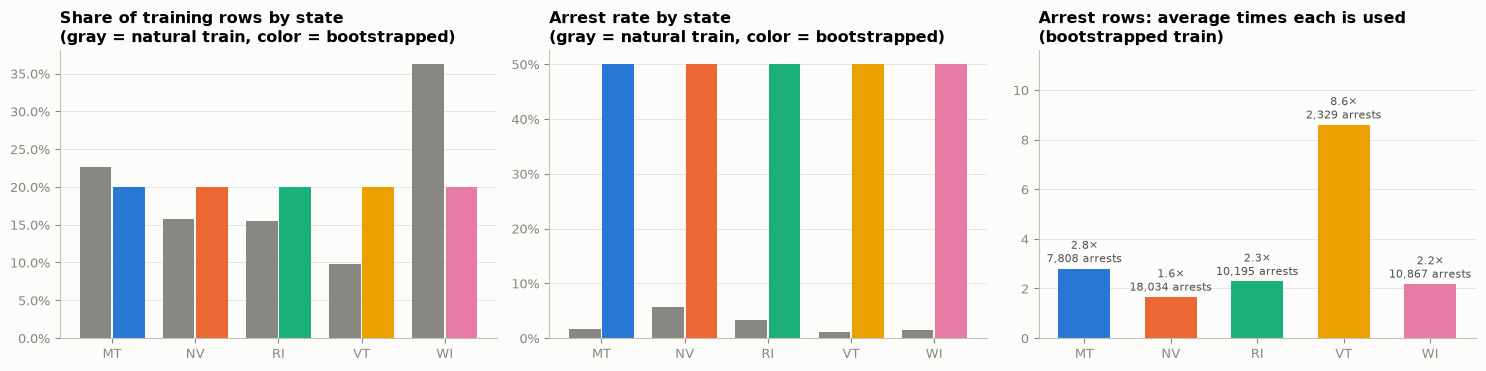

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
states = sorted(df_fe['state'].unique())

# composition: share of rows per state, natural vs balanced
ax = axes[0]
nat = train_natural['state'].value_counts(normalize=True).reindex(states)
bal = train_bal['state'].value_counts(normalize=True).reindex(states)
x = np.arange(len(states))
ax.bar(x - .2, nat, .38, color=MUTED, label='natural train')
ax.bar(x + .2, bal, .38, color=[STATE_COLOR[s] for s in states], label='bootstrapped train')
ax.set_xticks(x, states); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.grid(axis='x', visible=False)
ax.set_title('Share of training rows by state\n(gray = natural train, color = bootstrapped)')

# target balance per state
ax = axes[1]
nat_r = train_natural.groupby('state')['is_arrested'].mean().reindex(states)
bal_r = train_bal.groupby('state')['is_arrested'].mean().reindex(states)
ax.bar(x - .2, nat_r, .38, color=MUTED, label='natural train')
ax.bar(x + .2, bal_r, .38, color=[STATE_COLOR[s] for s in states], label='bootstrapped train')
ax.set_xticks(x, states); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.grid(axis='x', visible=False)
ax.set_title('Arrest rate by state\n(gray = natural train, color = bootstrapped)')

# duplication of the positive cells
ax = axes[2]
pos = boot_report[boot_report['is_arrested']].set_index('state').reindex(states)
bars = ax.bar(states, pos['times_each_row_used'], color=[STATE_COLOR[s] for s in states], width=.6)
ax.bar_label(bars, labels=[f'{v:.1f}×\n{a:,} arrests' for v, a in zip(pos['times_each_row_used'], pos['available'])],
             fontsize=8, color=INK2, padding=2)
ax.set_ylim(0, pos['times_each_row_used'].max() * 1.35); ax.grid(axis='x', visible=False)
ax.set_title('Arrest rows: average times each is used\n(bootstrapped train)')
plt.tight_layout(); plt.show()

**Sanity check: bootstrapping should not change what a row *looks like*, only how often each kind appears.** Within each cell, feature
means in the bootstrapped set should match the natural training set up to sampling noise.

In [11]:
check_cols = ['driver_age', 'hour', 'n_violations', 'vehicle_age', 'viol_speeding', 'vraw_license_suspended']
nat_means = train_natural.groupby(SPLIT_STRATA)[check_cols].mean()
bal_means = train_bal.groupby(SPLIT_STRATA)[check_cols].mean()
display(pd.concat({'natural': nat_means, 'bootstrapped': bal_means}, axis=1).swaplevel(axis=1).sort_index(axis=1)
          .style.format('{:.2f}', na_rep='–'))

### 2.5 Helpers for the modeling step

* **Prior correction.** Converts a probability from the balanced model back to the natural arrest rate of the stop's state.
  With `π_s` the state's natural training arrest rate and a balanced training prior of 0.5:
  `p_corrected = p·r / (p·r + 1 − p)`, where `r = π_s / (1 − π_s)`.
  It is monotonic within a state, so per-state ROC AUC is unchanged. It reorders stops *across* states, so pooled AP, F1 and ROC AUC
  should be computed on corrected probabilities.
* **Model matrices.** `make_xy` selects the feature set through `get_feature_columns` (§1.7) and uses its defaults unless
  overridden, e.g. `make_xy(test, include_post_stop=False)`, so every later model uses the same column list.

In [12]:
STATE_PRIOR = train_natural.groupby('state')['is_arrested'].mean()   # natural arrest rate per state (train only)
BALANCED_PRIOR = train_bal['is_arrested'].mean()                      # 0.5 by construction


def prior_correct(p, state, state_prior=STATE_PRIOR, train_prior=BALANCED_PRIOR):
    p = np.asarray(p, dtype=float)
    pi = pd.Series(state).map(state_prior).to_numpy()
    r = (pi / (1 - pi)) / (train_prior / (1 - train_prior))
    return p * r / (p * r + 1 - p)


def make_xy(d, **feature_kwargs):
    # feature_kwargs are passed to get_feature_columns (include_post_stop / include_sensitive); its defaults apply otherwise
    cols = get_feature_columns(**feature_kwargs)
    return d[cols], d[TARGET].astype(int)


X_train, y_train = make_xy(train_bal)
X_test, y_test = make_xy(test)
X_train_nat, y_train_nat = make_xy(train_natural)
import inspect
defaults = {k: v.default for k, v in inspect.signature(get_feature_columns).parameters.items()}
print(f'feature set: get_feature_columns{defaults} -> {X_train.shape[1]} columns')
print(f'X_train (bootstrapped) {X_train.shape}, positives {y_train.mean():.1%}')
print(f'X_train_nat (natural)  {X_train_nat.shape}, positives {y_train_nat.mean():.2%}')
print(f'X_test (natural)       {X_test.shape}, positives {y_test.mean():.2%}')

# example: a balanced-model score of 0.5 maps back to each state's natural base rate
demo = pd.DataFrame({'state': STATE_PRIOR.index, 'balanced_p': 0.5})
demo['corrected_p'] = prior_correct(demo['balanced_p'], demo['state'])
display(demo.style.format({'balanced_p': '{:.2f}', 'corrected_p': '{:.2%}'}).hide(axis='index'))

feature set: get_feature_columns{'include_post_stop': True, 'include_sensitive': False} -> 53 columns
X_train (bootstrapped) (200000, 53), positives 50.0%
X_train_nat (natural)  (2009919, 53), positives 2.45%
X_test (natural)       (861394, 53), positives 2.45%


state,balanced_p,corrected_p
MT,0.50,1.71%
NV,0.50,5.69%
RI,0.50,3.27%
VT,0.50,1.18%
WI,0.50,1.49%


## 3. Binary classification models

### 3.1 Approach

| Choice | What | Why |
|---|---|---|
| **Candidate models** | Logistic regression, random forest, HistGradientBoosting, LightGBM | A linear baseline, a bagged ensemble and two boosted ensembles. Boosted trees handle mixed types, missing values and the state-specific interactions found in the EDA. |
| **Training data** | `train_bal`: 200k bootstrapped rows, balanced by `state × is_arrested` (§2) | Equal weight to every state and both classes. |
| **Cross-validation** | 5-fold `StratifiedGroupKFold`, **grouped by `source_row`** | Bootstrapping duplicates rows. Without grouping, copies of the same stop land in both the training and validation folds, which inflates CV scores (VT arrests appear 8.6× each). |
| **Hyperparameter tuning** | `RandomizedSearchCV` over a search space per model, refit on **average precision** | AP is the headline metric for a rare positive class. ROC AUC is tracked alongside. |
| **F1 threshold** | Chosen on **out-of-fold** predictions of the tuned model, reweighted to the natural `state × is_arrested` mix and prior-corrected | F1 depends on prevalence. The threshold must be set on data shaped like production, without touching the test set. |
| **Final validation** | The untouched **30% natural test set** (861k stops, 2.45% arrests) | Every reported test metric reflects the real class balance. |

All probabilities are **prior-corrected** (§2.5) before computing metrics, so a score means "probability of arrest for a stop in this state".

In [13]:
import os
import time
import warnings
import cloudpickle
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, average_precision_score, f1_score,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve, brier_score_loss, log_loss)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
N_FOLDS = 5
CV = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
GROUPS = train_bal['source_row'].to_numpy()        # bootstrap duplicates of a stop stay in the same fold

### 3.2 Preprocessing

The engineered columns mix pandas `bool`, nullable `boolean` / `Int64`, floats, strings and categoricals. `FrameCaster` converts them
into two clean kinds, learned on the training data so unseen categories at inference become missing:
* **numeric**: every bool / int / float becomes `float64`, with `NaN` for missing values.
* **categorical**: strings and categoricals become a pandas `category` with a fixed category list.

Each model then gets the encoding it needs:

| Model | Categorical | Numeric |
|---|---|---|
| Logistic regression | one-hot, with rare levels (< 50 rows) pooled | median imputation + missing indicators, standardized |
| Random forest | ordinal codes, missing = −1 | missing → −1 |
| HistGradientBoosting | native categorical support | native missing-value support |
| LightGBM | native categorical support | native missing-value support |

In [14]:
class FrameCaster(BaseEstimator, TransformerMixin):
    # Turns the engineered frame into float64 numerics + fixed-category categoricals
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.cat_cols_ = [c for c in X.columns
                          if not (pd.api.types.is_numeric_dtype(X[c]) or pd.api.types.is_bool_dtype(X[c]))]
        self.num_cols_ = [c for c in X.columns if c not in self.cat_cols_]
        self.categories_ = {c: sorted(X[c].dropna().astype(str).unique()) for c in self.cat_cols_}
        self.feature_names_in_ = np.array(X.columns)
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        out = pd.DataFrame(index=X.index)
        for c in self.num_cols_:
            out[c] = X[c].astype('Float64').to_numpy(dtype='float64', na_value=np.nan)
        for c in self.cat_cols_:
            vals = X[c].astype(str).astype(object).where(X[c].notna())
            vals = vals.where(vals.isin(self.categories_[c]))                  # unseen levels -> NaN
            out[c] = pd.Categorical(vals, categories=self.categories_[c])
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(self.num_cols_ + self.cat_cols_)


def _cats_to_object(X):
    return X.astype(object).where(X.notna(), '__missing__')

CAT = make_column_selector(dtype_include='category')
NUM = make_column_selector(dtype_exclude='category')

def build_pipelines():
    return {
        'Logistic regression': Pipeline([
            ('cast', FrameCaster()),
            ('prep', ColumnTransformer([
                ('cat', Pipeline([('obj', FunctionTransformer(_cats_to_object)),
                                  ('ohe', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50,
                                                        sparse_output=True))]), CAT),
                ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                                  ('sc', StandardScaler())]), NUM)])),
            ('clf', LogisticRegression(max_iter=1000))]),
        'Random forest': Pipeline([
            ('cast', FrameCaster()),
            ('prep', ColumnTransformer([
                ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), CAT),
                ('num', SimpleImputer(strategy='constant', fill_value=-1), NUM)])),
            ('clf', RandomForestClassifier(n_estimators=200, max_samples=0.5, n_jobs=-1, random_state=SEED))]),
        'HistGradientBoosting': Pipeline([
            ('cast', FrameCaster()),
            ('clf', HistGradientBoostingClassifier(categorical_features='from_dtype', early_stopping=False,
                                                   random_state=SEED))]),
        'LightGBM': Pipeline([
            ('cast', FrameCaster()),
            ('clf', LGBMClassifier(subsample_freq=1, n_jobs=-1, verbose=-1, random_state=SEED))]),
    }

SEARCH_SPACES = {
    'Logistic regression': ({'clf__C': loguniform(1e-3, 10)}, 6),
    'Random forest': ({'clf__max_depth': [12, 18, 26], 'clf__min_samples_leaf': [10, 30, 100],
                       'clf__max_features': ['sqrt', 0.25, 0.4]}, 6),
    'HistGradientBoosting': ({'clf__learning_rate': loguniform(0.03, 0.2), 'clf__max_iter': [200, 400],
                              'clf__max_leaf_nodes': [31, 63, 127], 'clf__min_samples_leaf': [20, 100, 300],
                              'clf__l2_regularization': loguniform(1e-3, 10)}, 8),
    'LightGBM': ({'clf__n_estimators': [300, 600], 'clf__learning_rate': loguniform(0.02, 0.15),
                  'clf__num_leaves': [31, 63, 127], 'clf__min_child_samples': [20, 100, 300],
                  'clf__subsample': [0.7, 0.9], 'clf__colsample_bytree': [0.6, 0.8, 1.0],
                  'clf__reg_lambda': loguniform(1e-3, 10)}, 10),
}
PIPELINES = build_pipelines()
caster_preview = FrameCaster().fit(X_train)
print(f'{X_train.shape[1]} features -> {len(caster_preview.num_cols_)} numeric, {len(caster_preview.cat_cols_)} categorical:',
      caster_preview.cat_cols_)

53 features -> 47 numeric, 6 categorical: ['state', 'day_of_week', 'geo_unit', 'police_department', 'road_class', 'interstate_id']


### 3.2.1 The four candidate models

**1. Logistic regression (baseline)**
* *What:* a linear model on one-hot categoricals and standardized numerics. The log-odds of arrest are a weighted sum of the features.
* *Why included:* the interpretable reference point. If a complex model cannot clearly beat it, the complexity is not worth it.
* *Tuned:* `C`, the inverse L2 regularization strength (log-uniform 0.001–10).
* *Strengths:* fast, stable, coefficients are directly interpretable, well-behaved probabilities.
* *Weaknesses:* no interactions unless hand-built. The EDA showed the same feature behaving differently per state (e.g. vehicle age matters in WI, not MT), which a single linear model cannot express.

**2. Random forest**
* *What:* 200 decision trees, each grown on a random half of the rows and a random subset of features. Their votes are averaged.
* *Why included:* a strong non-linear baseline that captures interactions automatically and is robust to noisy features.
* *Tuned:* `max_depth` (12/18/26), `min_samples_leaf` (10/30/100), `max_features` (sqrt / 25% / 40%).
* *Strengths:* little tuning needed, hard to overfit badly, captures state × feature interactions.
* *Weaknesses:* ordinal codes for categoricals are arbitrary. Probabilities tend to be compressed toward the middle. Large on disk and slow to score.

**3. HistGradientBoosting (scikit-learn)**
* *What:* gradient-boosted trees built sequentially, each correcting the previous ones' errors, on binned features with native categorical and missing-value handling.
* *Why included:* boosting is usually the strongest family on tabular data. This is scikit-learn's implementation, with no extra dependency.
* *Tuned:* `learning_rate` (0.03–0.2), `max_iter` (200/400 trees), `max_leaf_nodes` (31/63/127), `min_samples_leaf` (20/100/300), `l2_regularization` (0.001–10).
* *Strengths:* high accuracy, native handling of the many missing-by-state fields, fast.
* *Weaknesses:* more hyperparameters, and it can overfit duplicated minority rows (VT) without regularization.

**4. LightGBM**
* *What:* gradient-boosted trees with leaf-wise growth, row/column subsampling and native categorical splits.
* *Why included:* the industry-standard boosting library. Its subsampling and regularization options suit a bootstrapped training set.
* *Tuned:* `n_estimators` (300/600), `learning_rate` (0.02–0.15), `num_leaves` (31/63/127), `min_child_samples` (20/100/300), `subsample` (0.7/0.9), `colsample_bytree` (0.6/0.8/1.0), `reg_lambda` (0.001–10).
* *Strengths:* typically the best accuracy/speed trade-off, small model file, exposes feature importance.
* *Weaknesses:* the most hyperparameters, and leaf-wise growth can overfit if `min_child_samples` is too small.

The search budgets (6 / 6 / 8 / 10 configurations) scale with each model's search-space size and fit cost.

### 3.3 Hyperparameter tuning with 5-fold grouped cross-validation

Each model's search samples `n_iter` configurations, scores each with 5-fold grouped CV, and refits the best (by AP) on all of
`train_bal`. The out-of-fold (OOF) predictions of the best configuration are then collected for threshold selection (§3.4).

Four CV metrics are recorded for every configuration: **AP** (used to pick the best), **ROC AUC**, and **F1** and **accuracy** at the
default 0.5 cut-off.

*Note:* CV metrics are measured on balanced folds (50% arrests), so they are higher than the natural-prevalence test metrics in §4.
In particular, CV accuracy and F1 at 0.5 describe a 50/50 world. They are used to **compare** configurations, not to estimate
production performance.

In [15]:
searches, oof, timings = {}, {}, {}


def tune_model(name):
    # randomized search with grouped 5-fold CV, then out-of-fold predictions of the best configuration
    pipe = PIPELINES[name]
    space, n_iter = SEARCH_SPACES[name]
    t0 = time.time()
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=CV,
                                scoring={'ap': 'average_precision', 'auc': 'roc_auc', 'f1': 'f1', 'accuracy': 'accuracy'},
                                refit='ap', n_jobs=(-1 if name == 'Logistic regression' else 1), random_state=SEED,
                                return_train_score=True, error_score='raise')
    search.fit(X_train, y_train, groups=GROUPS)
    t_search = time.time() - t0
    t0 = time.time()
    oof[name] = cross_val_predict(clone(search.best_estimator_), X_train, y_train, groups=GROUPS, cv=CV,
                                  method='predict_proba')[:, 1]
    searches[name] = search
    timings[name] = {'search_s': t_search, 'oof_s': time.time() - t0}
    best = search.best_index_
    r = search.cv_results_
    print(f"{name}: {n_iter} configs x {N_FOLDS} folds in {t_search/60:.1f} min (+{timings[name]['oof_s']/60:.1f} min OOF)\n"
          f"  best CV  AP {r['mean_test_ap'][best]:.4f} ± {r['std_test_ap'][best]:.4f} | AUC {r['mean_test_auc'][best]:.4f} | "
          f"F1 {r['mean_test_f1'][best]:.4f} | accuracy {r['mean_test_accuracy'][best]:.4f} | train AP {r['mean_train_ap'][best]:.4f}\n"
          f"  best params {search.best_params_}")

One cell per model, so each model's tuning result is visible as soon as it finishes.

In [16]:
tune_model('Logistic regression')

Logistic regression: 6 configs x 5 folds in 5.0 min (+2.5 min OOF)
  best CV  AP 0.8873 ± 0.0047 | AUC 0.8842 | F1 0.7793 | accuracy 0.7924 | train AP 0.8888
  best params {'clf__C': np.float64(0.24810409748678125)}


In [17]:
tune_model('Random forest')

Random forest: 6 configs x 5 folds in 15.3 min (+3.5 min OOF)
  best CV  AP 0.9072 ± 0.0031 | AUC 0.8995 | F1 0.8070 | accuracy 0.8163 | train AP 0.9524
  best params {'clf__min_samples_leaf': 10, 'clf__max_features': 0.25, 'clf__max_depth': 26}


In [18]:
tune_model('HistGradientBoosting')

HistGradientBoosting: 8 configs x 5 folds in 23.3 min (+0.8 min OOF)
  best CV  AP 0.9150 ± 0.0034 | AUC 0.9092 | F1 0.8192 | accuracy 0.8257 | train AP 0.9514
  best params {'clf__l2_regularization': np.float64(0.004207988669606638), 'clf__learning_rate': np.float64(0.0403316977206044), 'clf__max_iter': 200, 'clf__max_leaf_nodes': 127, 'clf__min_samples_leaf': 20}


In [19]:
tune_model('LightGBM')

LightGBM: 10 configs x 5 folds in 34.6 min (+0.8 min OOF)
  best CV  AP 0.9168 ± 0.0031 | AUC 0.9099 | F1 0.8176 | accuracy 0.8274 | train AP 0.9728
  best params {'clf__colsample_bytree': 0.8, 'clf__learning_rate': np.float64(0.03694755509074355), 'clf__min_child_samples': 20, 'clf__n_estimators': 600, 'clf__num_leaves': 127, 'clf__reg_lambda': np.float64(0.5408216580718497), 'clf__subsample': 0.9}


,configs_tried,cv_ap_mean,cv_ap_std,cv_auc_mean,cv_auc_std,cv_f1_mean,cv_accuracy_mean,train_ap,overfit_gap_ap,search_min,best_params
model,,,,,,,,,,,
Logistic regression,6,0.8873,0.0047,0.8842,0.0048,0.7793,0.7924,0.8888,+0.0016,5.0,{'C': np.float64(0.2481)}
Random forest,6,0.9072,0.0031,0.8995,0.0035,0.8070,0.8163,0.9524,+0.0451,15.3,"{'min_samples_leaf': 10, 'max_features': 0.25, 'max_depth': 26}"
HistGradientBoosting,8,0.9150,0.0034,0.9092,0.0037,0.8192,0.8257,0.9514,+0.0364,23.3,"{'l2_regularization': np.float64(0.0042), 'learning_rate': np.float64(0.0403), 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}"
LightGBM,10,0.9168,0.0031,0.9099,0.0034,0.8176,0.8274,0.9728,+0.0559,34.6,"{'colsample_bytree': 0.8, 'learning_rate': np.float64(0.0369), 'min_child_samples': 20, 'n_estimators': 600, 'num_leaves': 127, 'reg_lambda': np.float64(0.5408), 'subsample': 0.9}"


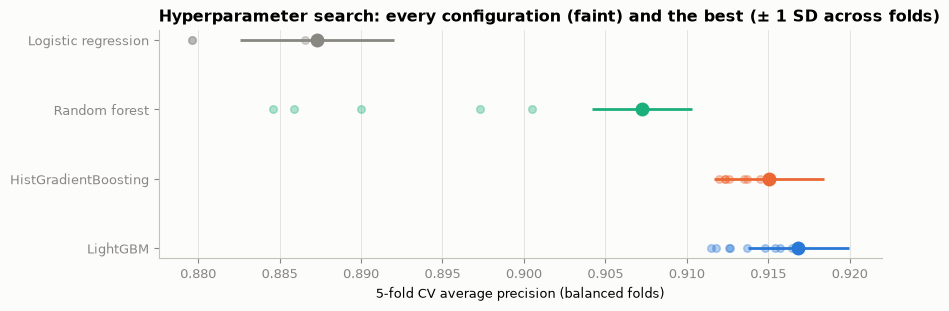

In [20]:
cv_rows = []
for name, s in searches.items():
    r, b = s.cv_results_, s.best_index_
    cv_rows.append({'model': name, 'configs_tried': len(r['params']),
                    'cv_ap_mean': r['mean_test_ap'][b], 'cv_ap_std': r['std_test_ap'][b],
                    'cv_auc_mean': r['mean_test_auc'][b], 'cv_auc_std': r['std_test_auc'][b],
                    'cv_f1_mean': r['mean_test_f1'][b], 'cv_accuracy_mean': r['mean_test_accuracy'][b],
                    'train_ap': r['mean_train_ap'][b], 'overfit_gap_ap': r['mean_train_ap'][b] - r['mean_test_ap'][b],
                    'search_min': timings[name]['search_s'] / 60,
                    'best_params': {k.replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v)
                                    for k, v in s.best_params_.items()}})
cv_summary = pd.DataFrame(cv_rows).set_index('model')
display(cv_summary.style.format({'cv_ap_mean': '{:.4f}', 'cv_ap_std': '{:.4f}', 'cv_auc_mean': '{:.4f}', 'cv_auc_std': '{:.4f}',
                                 'cv_f1_mean': '{:.4f}', 'cv_accuracy_mean': '{:.4f}',
                                 'train_ap': '{:.4f}', 'overfit_gap_ap': '{:+.4f}', 'search_min': '{:.1f}'}))

MODELS = list(PIPELINES)
MODEL_COLOR = dict(zip(MODELS, ['#898781', '#1baf7a', '#eb6834', '#2a78d6']))
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, name in enumerate(MODELS):
    r = searches[name].cv_results_
    ax.scatter(r['mean_test_ap'], np.full(len(r['params']), i), color=MODEL_COLOR[name], alpha=.35, s=30)
    b = searches[name].best_index_
    ax.errorbar(r['mean_test_ap'][b], i, xerr=r['std_test_ap'][b], fmt='o', color=MODEL_COLOR[name], ms=9,
                capsize=0, elinewidth=2)
ax.set_yticks(range(len(MODELS)), MODELS); ax.grid(axis='y', visible=False); ax.invert_yaxis()
ax.set_xlabel('5-fold CV average precision (balanced folds)')
ax.set_title('Hyperparameter search: every configuration (faint) and the best (± 1 SD across folds)')
plt.tight_layout(); plt.show()

#### Full tuning record: every configuration of every model
Each row is one configuration scored by 5-fold grouped CV (`rank` 1 = best AP within its model). The per-fold AP columns show how stable each
configuration is.

In [21]:
all_rows = []
for name, s in searches.items():
    r = pd.DataFrame(s.cv_results_)
    params = pd.json_normalize(r['params']).rename(columns=lambda c: c.replace('clf__', ''))
    folds = r[[f'split{k}_test_ap' for k in range(N_FOLDS)]].rename(columns=lambda c: c.replace('split', 'fold').replace('_test_ap', '_ap'))
    rec = pd.concat([r[['rank_test_ap', 'mean_test_ap', 'std_test_ap', 'mean_test_auc', 'mean_test_f1', 'mean_test_accuracy',
                        'mean_train_ap', 'mean_fit_time']]
                       .rename(columns={'rank_test_ap': 'rank', 'mean_test_ap': 'cv_ap', 'std_test_ap': 'cv_ap_std',
                                        'mean_test_auc': 'cv_auc', 'mean_test_f1': 'cv_f1', 'mean_test_accuracy': 'cv_accuracy',
                                        'mean_train_ap': 'train_ap', 'mean_fit_time': 'fit_s'}),
                     folds, params], axis=1)
    rec.insert(0, 'model', name)
    all_rows.append(rec.sort_values('rank'))
cv_all = pd.concat(all_rows, ignore_index=True)
num_fmt = {c: '{:.4f}' for c in cv_all.columns if c.startswith(('cv_', 'train_', 'fold'))} | {'fit_s': '{:.1f}'}
for name in MODELS:
    sub = cv_all[cv_all.model == name].dropna(axis=1, how='all')
    display(sub.style.format(num_fmt | {c: '{:.4g}' for c in sub.columns if sub[c].dtype == float and c not in num_fmt}, na_rep='')
              .hide(axis='index').set_caption(f'{name}: {len(sub)} configurations')
              .apply(lambda r: ['font-weight: bold' if r['rank'] == 1 else '' for _ in r], axis=1))

model,rank,cv_ap,cv_ap_std,cv_auc,cv_f1,cv_accuracy,train_ap,fit_s,fold0_ap,fold1_ap,fold2_ap,fold3_ap,fold4_ap,C
Logistic regression,1,0.8873,0.0047,0.8842,0.7793,0.7924,0.8888,70.0,0.8918,0.8929,0.8800,0.8871,0.8846,0.2481
Logistic regression,2,0.8873,0.0047,0.8842,0.7799,0.7927,0.8889,79.2,0.8918,0.8928,0.8800,0.8869,0.8846,0.8472
Logistic regression,3,0.8872,0.0047,0.8841,0.7802,0.7929,0.8889,81.5,0.8919,0.8928,0.8800,0.8869,0.8847,6.351
Logistic regression,4,0.8866,0.0048,0.8830,0.7776,0.7916,0.8878,54.0,0.8904,0.8928,0.8794,0.8865,0.8837,0.03149
Logistic regression,5,0.8796,0.0049,0.8740,0.7661,0.7841,0.8805,38.9,0.8827,0.8867,0.8724,0.8793,0.8769,0.004208
Logistic regression,6,0.8796,0.0049,0.8740,0.7661,0.7841,0.8805,39.8,0.8827,0.8867,0.8724,0.8793,0.8769,0.004207


model,rank,cv_ap,cv_ap_std,cv_auc,cv_f1,cv_accuracy,train_ap,fit_s,fold0_ap,fold1_ap,fold2_ap,fold3_ap,fold4_ap,min_samples_leaf,max_features,max_depth
Random forest,1,0.9072,0.0031,0.8995,0.8070,0.8163,0.9524,26.3,0.9086,0.9119,0.9024,0.9070,0.9063,10,0.250000,26
Random forest,2,0.9005,0.0037,0.8935,0.8040,0.8099,0.9195,24.9,0.9022,0.9060,0.8946,0.8998,0.8999,30,0.250000,18
Random forest,3,0.8973,0.0036,0.8898,0.7953,0.8048,0.9260,17.6,0.8987,0.9030,0.8919,0.8966,0.8963,10,sqrt,18
Random forest,4,0.8900,0.0042,0.8821,0.7884,0.7938,0.8960,20.0,0.8916,0.8960,0.8830,0.8894,0.8900,100,0.400000,12
Random forest,5,0.8859,0.0043,0.8769,0.7755,0.7885,0.8978,15.6,0.8873,0.8926,0.8793,0.8849,0.8853,10,sqrt,12
Random forest,6,0.8846,0.0041,0.8758,0.7813,0.7903,0.8913,13.4,0.8865,0.8906,0.8782,0.8838,0.8836,100,sqrt,18


model,rank,cv_ap,cv_ap_std,cv_auc,cv_f1,cv_accuracy,train_ap,fit_s,fold0_ap,fold1_ap,fold2_ap,fold3_ap,fold4_ap,min_samples_leaf,l2_regularization,learning_rate,max_iter,max_leaf_nodes
HistGradientBoosting,1,0.9150,0.0034,0.9092,0.8192,0.8257,0.9514,29.4,0.9164,0.9200,0.9097,0.9157,0.9134,20,0.004208,0.04033,200,127
HistGradientBoosting,2,0.9145,0.0036,0.9077,0.8156,0.8257,0.9754,49.5,0.9158,0.9189,0.9085,0.9163,0.9128,100,0.1256,0.06406,400,127
HistGradientBoosting,3,0.9137,0.0037,0.9080,0.8186,0.8252,0.9552,20.6,0.9152,0.9190,0.9077,0.9140,0.9126,100,0.2538,0.1149,400,31
HistGradientBoosting,4,0.9135,0.0036,0.9083,0.8201,0.8258,0.9489,19.2,0.9151,0.9190,0.9080,0.9137,0.9117,20,0.01648,0.08118,400,31
HistGradientBoosting,5,0.9126,0.0034,0.9073,0.8201,0.8245,0.9358,3.4,0.9139,0.9176,0.9072,0.9132,0.9109,300,0.001534,0.09499,200,31
HistGradientBoosting,6,0.9124,0.0029,0.9045,0.8093,0.8224,0.9858,48.5,0.9132,0.9158,0.9072,0.9137,0.9119,20,0.002304,0.09696,400,127
HistGradientBoosting,7,0.9123,0.0035,0.9060,0.8150,0.8236,0.9660,20.1,0.9125,0.9172,0.9067,0.9140,0.9113,20,0.7727,0.178,400,31
HistGradientBoosting,8,0.9120,0.0034,0.9065,0.8172,0.8236,0.9511,9.7,0.9129,0.9167,0.9065,0.9133,0.9104,20,0.03149,0.1821,200,31


model,rank,cv_ap,cv_ap_std,cv_auc,cv_f1,cv_accuracy,train_ap,fit_s,fold0_ap,fold1_ap,fold2_ap,fold3_ap,fold4_ap,learning_rate,colsample_bytree,min_child_samples,n_estimators,num_leaves,reg_lambda,subsample
LightGBM,1,0.9168,0.0031,0.9099,0.8176,0.8274,0.9728,6.2,0.9182,0.9212,0.9122,0.9178,0.9147,0.03695,0.8,20,600,127,0.5408,0.9
LightGBM,2,0.9164,0.0033,0.9105,0.8202,0.8279,0.9600,3.6,0.9178,0.9214,0.9116,0.9167,0.9148,0.04711,0.8,100,600,63,0.001334,0.9
LightGBM,3,0.9157,0.0035,0.9106,0.8225,0.8286,0.9482,3.6,0.9176,0.9206,0.9104,0.9163,0.9138,0.0694,0.6,100,600,31,0.05343,0.7
LightGBM,4,0.9154,0.0029,0.9099,0.8202,0.8273,0.9557,3.4,0.9172,0.9188,0.9104,0.9164,0.9141,0.1072,0.6,300,600,31,0.01084,0.9
LightGBM,5,0.9148,0.0035,0.9094,0.8213,0.8266,0.9428,4.1,0.9163,0.9202,0.9096,0.9148,0.9131,0.02085,1,100,600,63,0.007069,0.9
LightGBM,6,0.9137,0.0030,0.9086,0.8198,0.8255,0.9435,1.6,0.9152,0.9181,0.9091,0.9140,0.9120,0.09955,1,300,300,31,0.244,0.9
LightGBM,7,0.9127,0.0029,0.9039,0.8076,0.8213,0.9851,6.2,0.9139,0.9166,0.9079,0.9132,0.9118,0.06862,1,100,600,127,0.06672,0.7
LightGBM,8,0.9126,0.0034,0.9081,0.8209,0.8253,0.9318,6.9,0.9145,0.9176,0.9074,0.9126,0.9109,0.02991,0.8,300,600,31,0.001534,0.7
LightGBM,9,0.9118,0.0034,0.9072,0.8203,0.8247,0.9319,318.5,0.9133,0.9171,0.9066,0.9117,0.9103,0.0282,1,300,600,31,7.287,0.9
LightGBM,10,0.9115,0.0037,0.9068,0.8208,0.8249,0.9303,3.1,0.9135,0.9170,0.9060,0.9110,0.9099,0.02446,1,300,600,31,0.2538,0.9


### 3.4 Choosing the F1 threshold on out-of-fold predictions

The OOF predictions come from 50/50 balanced folds. To make them look like production, two adjustments are made:
1. **Prior correction** (§2.5) maps each probability back to its state's natural arrest rate.
2. **Reweighting**: each OOF row gets weight `natural count of its (state, label) cell ÷ 20,000`. The weighted OOF set then has the
   natural train mix of states and arrests.

The threshold that maximizes weighted F1 is used unchanged on the test set.

In [22]:
cell_n = train_natural.groupby(['state', 'is_arrested']).size()
oof_weight = (train_bal[['state', 'is_arrested']].merge(cell_n.rename('n').reset_index(), on=['state', 'is_arrested'],
                                                       how='left')['n'].to_numpy() / N_PER_CELL)


def best_f1_threshold(y, p, w):
    prec, rec, thr = precision_recall_curve(y, p, sample_weight=w)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return thr[i], f1[i]

thresholds = {}
for name in MODELS:
    p_oof = np.clip(prior_correct(oof[name], train_bal["state"]), 0, 1)   # clip float round-off
    thresholds[name], f1_oof = best_f1_threshold(y_train, p_oof, oof_weight)
    print(f'{name:22s} F1-optimal threshold {thresholds[name]:.3f} (weighted OOF F1 {f1_oof:.3f})')

Logistic regression    F1-optimal threshold 0.199 (weighted OOF F1 0.417)
Random forest          F1-optimal threshold 0.173 (weighted OOF F1 0.474)
HistGradientBoosting   F1-optimal threshold 0.170 (weighted OOF F1 0.486)
LightGBM               F1-optimal threshold 0.196 (weighted OOF F1 0.496)


## 4. Evaluation on the non-bootstrapped test set

All four tuned models score the **30% natural test set** (861,394 stops, 2.45% arrests), which was never used for
training, tuning or threshold selection.

Metrics:
* **Average precision (AP)**: area under the precision-recall curve. The headline metric for a rare positive class. A random model scores the base rate (0.0245).
* **ROC AUC**: ranking quality, independent of prevalence.
* **F1 / precision / recall** at the OOF-chosen threshold.
* **Accuracy** at the same threshold, plus **balanced accuracy** (the mean of the recall on arrests and on non-arrests).
  With 2.45% arrests, a model that predicts "no arrest" for every stop is already **97.55% accurate**. Accuracy is therefore shown
  next to that all-negative baseline, and should not be used alone to rank models.
* **Brier score** and **log loss**: quality of the probabilities themselves (lower is better).

In [23]:
p_test = {}
for name in MODELS:
    t0 = time.time()
    raw_p = searches[name].best_estimator_.predict_proba(X_test)[:, 1]
    p_test[name] = np.clip(prior_correct(raw_p, test["state"]), 0, 1)               # clip float round-off
    timings[name]['predict_s'] = time.time() - t0


def evaluate(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {'average_precision': average_precision_score(y, p), 'roc_auc': roc_auc_score(y, p),
            'f1': f1_score(y, yhat), 'accuracy': accuracy_score(y, yhat),
            'balanced_accuracy': balanced_accuracy_score(y, yhat), 'precision': precision_score(y, yhat, zero_division=0),
            'recall': recall_score(y, yhat), 'threshold': thr,
            'brier': brier_score_loss(y, p), 'log_loss': log_loss(y, np.clip(p, 1e-7, 1 - 1e-7))}

test_metrics = pd.DataFrame({name: evaluate(y_test, p_test[name], thresholds[name]) for name in MODELS}).T
test_metrics['predict_s'] = [timings[m]['predict_s'] for m in MODELS]
test_metrics = test_metrics.sort_values('average_precision', ascending=False)
ALL_NEGATIVE_ACCURACY = 1 - y_test.mean()
display(test_metrics.style.format({c: '{:.4f}' for c in test_metrics.columns if c != 'predict_s'} | {'predict_s': '{:.1f}'})
        .highlight_max(subset=['average_precision', 'roc_auc', 'f1', 'accuracy', 'balanced_accuracy'], color='#cde2fb')
        .highlight_min(subset=['brier', 'log_loss'], color='#cde2fb')
        .set_caption(f'Test set: {len(y_test):,} stops, base rate {y_test.mean():.4f}; '
                     f'"always no arrest" baseline accuracy {ALL_NEGATIVE_ACCURACY:.4f}'))
print('accuracy gain over always predicting "no arrest" (percentage points):')
print((100 * (test_metrics['accuracy'] - ALL_NEGATIVE_ACCURACY)).round(3).to_string())

,average_precision,roc_auc,f1,accuracy,balanced_accuracy,precision,recall,threshold,brier,log_loss,predict_s
LightGBM,0.4759,0.9314,0.4966,0.9754,0.7411,0.4985,0.4946,0.1956,0.0167,0.0672,12.4
HistGradientBoosting,0.4705,0.9296,0.4855,0.9739,0.7441,0.4698,0.5023,0.1697,0.0170,0.0681,5.3
Random forest,0.4460,0.9211,0.4750,0.9758,0.7177,0.5077,0.4463,0.1731,0.0176,0.0710,4.4
Logistic regression,0.3190,0.9058,0.4116,0.9682,0.7173,0.3767,0.4535,0.1993,0.0197,0.0793,4.4


accuracy gain over always predicting "no arrest" (percentage points):
LightGBM               -0.007
HistGradientBoosting   -0.158
Random forest           0.033
Logistic regression    -0.727


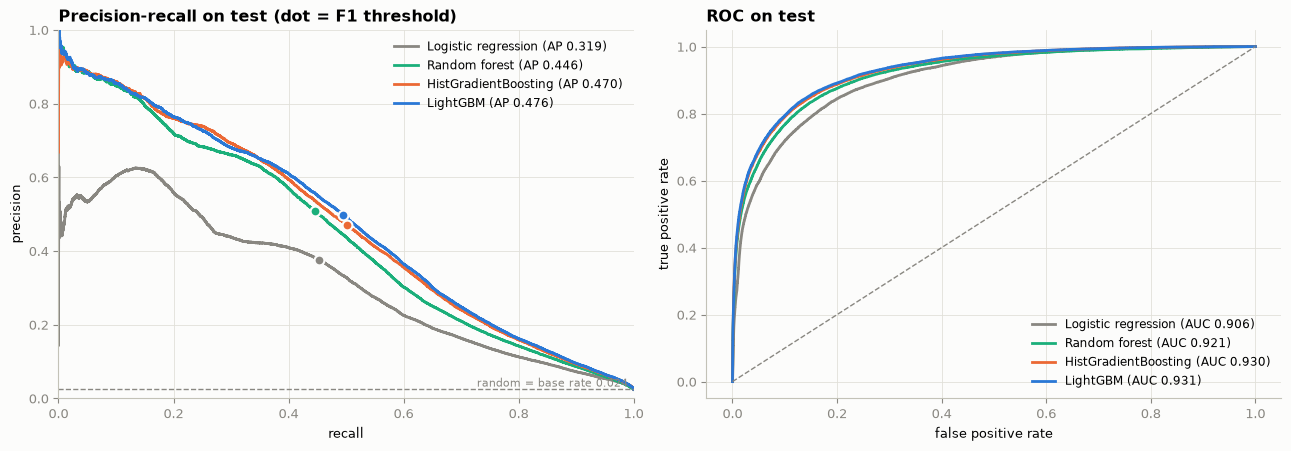

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
for name in MODELS:
    prec, rec, _ = precision_recall_curve(y_test, p_test[name])
    ax.plot(rec, prec, color=MODEL_COLOR[name], lw=2,
            label=f"{name} (AP {test_metrics.loc[name, 'average_precision']:.3f})")
    thr = thresholds[name]
    yhat = p_test[name] >= thr
    ax.scatter(recall_score(y_test, yhat), precision_score(y_test, yhat), color=MODEL_COLOR[name], s=50,
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axhline(y_test.mean(), color=MUTED, lw=1, ls='--')
ax.annotate(f'random = base rate {y_test.mean():.3f}', (0.99, y_test.mean()), ha='right', va='bottom', fontsize=8, color=MUTED)
ax.set_xlabel('recall'); ax.set_ylabel('precision'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title('Precision-recall on test (dot = F1 threshold)'); ax.legend(fontsize=8.5, frameon=False, loc='upper right')

ax = axes[1]
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, p_test[name])
    ax.plot(fpr, tpr, color=MODEL_COLOR[name], lw=2, label=f"{name} (AUC {test_metrics.loc[name, 'roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls='--')
ax.set_xlabel('false positive rate'); ax.set_ylabel('true positive rate')
ax.set_title('ROC on test'); ax.legend(fontsize=8.5, frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

### 4.1 Performance by state

A pooled metric can hide a state where the model fails, so AP, ROC AUC, F1, accuracy and balanced accuracy are also computed
**within each state** of the test set. Within-state AP is compared with that state's base rate, since a random model's AP equals the
base rate. Within-state accuracy should be read against that state's "always no arrest" accuracy (1 − base rate).

In [25]:
rows = []
for name in MODELS:
    for s, idx in test.groupby('state').indices.items():
        yt, pt = y_test.iloc[idx], p_test[name][idx]
        yhat = (pt >= thresholds[name]).astype(int)
        rows.append({'model': name, 'state': s, 'base_rate': yt.mean(), 'AP': average_precision_score(yt, pt),
                     'ROC AUC': roc_auc_score(yt, pt), 'F1': f1_score(yt, yhat), 'Accuracy': accuracy_score(yt, yhat),
                     'Balanced accuracy': balanced_accuracy_score(yt, yhat)})
by_state = pd.DataFrame(rows)
by_state['AP_lift'] = by_state['AP'] / by_state['base_rate']
wide = by_state.pivot(index='model', columns='state',
                      values=['AP', 'ROC AUC', 'F1', 'Accuracy', 'Balanced accuracy']).reindex(test_metrics.index)
display(wide.style.format('{:.3f}').background_gradient(cmap='Blues', axis=0))
display(by_state.groupby('state')[['base_rate']].first().T.style.format('{:.4f}').set_caption('test base rate by state'))

state,MT,NV,RI,VT,WI
base_rate,0.0171,0.0569,0.0327,0.0118,0.0149


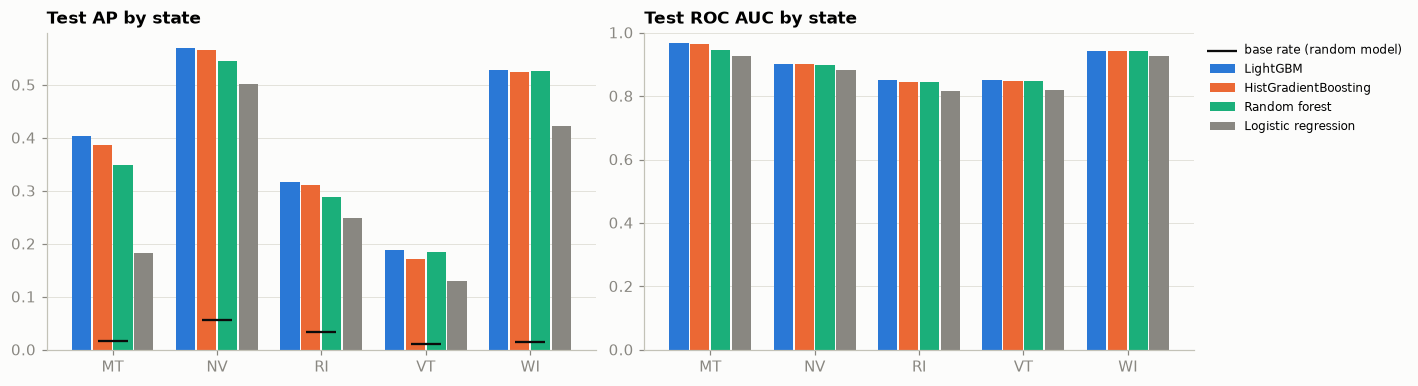

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
states = sorted(test['state'].unique())
x = np.arange(len(states)); w = .8 / len(MODELS)
for j, metric in enumerate(['AP', 'ROC AUC']):
    ax = axes[j]
    for i, name in enumerate(test_metrics.index):
        vals = by_state[by_state.model == name].set_index('state').reindex(states)[metric]
        ax.bar(x + (i - (len(MODELS) - 1) / 2) * w, vals, w * .92, color=MODEL_COLOR[name], label=name)
    if metric == 'AP':
        base = by_state.groupby('state')['base_rate'].first().reindex(states)
        ax.scatter(x, base, marker='_', s=400, color='#0b0b0b', zorder=3, label='base rate (random model)')
    ax.set_xticks(x, states); ax.grid(axis='x', visible=False)
    ax.set_ylim(0, 1 if metric == 'ROC AUC' else None)
    ax.set_title(f'Test {metric} by state')
axes[1].legend(*axes[0].get_legend_handles_labels(), fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

### 4.2 What drives the best boosted model
LightGBM split-gain importance (share of total gain), top 25 features.

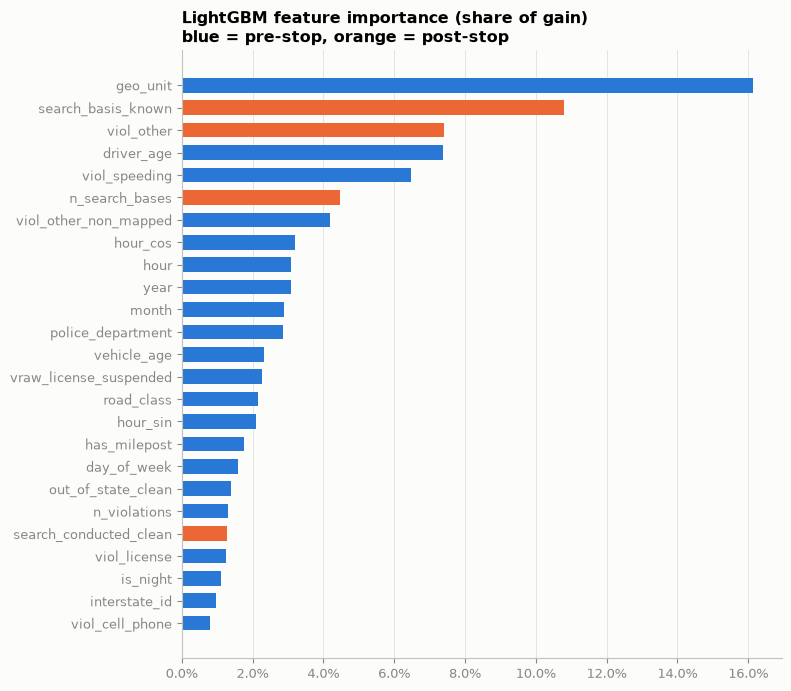

post-stop features account for 24.0% of the top-25 gain


In [27]:
lgbm = searches['LightGBM'].best_estimator_
gain = pd.Series(lgbm.named_steps['clf'].booster_.feature_importance(importance_type='gain'),
                 index=lgbm.named_steps['cast'].get_feature_names_out())
gain = (gain / gain.sum()).sort_values(ascending=False).head(25)[::-1]
post = set(FEATURE_SETS['POST_STOP'])
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(gain.index, gain.values, color=['#eb6834' if f in post else '#2a78d6' for f in gain.index], height=.65)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.grid(axis='y', visible=False)
ax.set_title('LightGBM feature importance (share of gain)\nblue = pre-stop, orange = post-stop')
plt.tight_layout(); plt.show()
print(f"post-stop features account for {gain[gain.index.isin(post)].sum():.1%} of the top-25 gain")

### 4.3 Side-by-side scorecard
Every criterion used to pick the winner, in one table: test metrics, worst-state performance, CV stability, overfitting and cost.

In [28]:
scorecard = test_metrics[['average_precision', 'roc_auc', 'f1', 'accuracy', 'balanced_accuracy', 'precision', 'recall',
                          'brier']].copy()
scorecard['worst_state_AP_lift'] = by_state.groupby('model')['AP_lift'].min()
scorecard['worst_state_AUC'] = by_state.groupby('model')['ROC AUC'].min()
scorecard['cv_ap'] = cv_summary['cv_ap_mean']
scorecard['cv_ap_std'] = cv_summary['cv_ap_std']
scorecard['train_minus_cv_ap'] = cv_summary['overfit_gap_ap']
scorecard['search_min'] = cv_summary['search_min']
scorecard['predict_s_861k'] = test_metrics['predict_s']
scorecard['test_AP_rank'] = scorecard['average_precision'].rank(ascending=False).astype(int)
display(scorecard.sort_values('test_AP_rank').style
        .format('{:.4f}').format('{:.1f}', subset=['search_min', 'predict_s_861k']).format('{:d}', subset=['test_AP_rank'])
        .format('{:.1f}×', subset=['worst_state_AP_lift'])
        .highlight_max(subset=['average_precision', 'roc_auc', 'f1', 'accuracy', 'balanced_accuracy', 'worst_state_AP_lift',
                               'worst_state_AUC'], color='#cde2fb')
        .highlight_min(subset=['brier', 'cv_ap_std', 'train_minus_cv_ap'], color='#cde2fb'))

,average_precision,roc_auc,f1,accuracy,balanced_accuracy,precision,recall,brier,worst_state_AP_lift,worst_state_AUC,cv_ap,cv_ap_std,train_minus_cv_ap,search_min,predict_s_861k,test_AP_rank
LightGBM,0.4759,0.9314,0.4966,0.9754,0.7411,0.4985,0.4946,0.0167,9.7×,0.8501,0.9168,0.0031,0.0559,34.6,12.4,1
HistGradientBoosting,0.4705,0.9296,0.4855,0.9739,0.7441,0.4698,0.5023,0.0170,9.5×,0.8459,0.9150,0.0034,0.0364,23.3,5.3,2
Random forest,0.4460,0.9211,0.4750,0.9758,0.7177,0.5077,0.4463,0.0176,8.8×,0.8448,0.9072,0.0031,0.0451,15.3,4.4,3
Logistic regression,0.3190,0.9058,0.4116,0.9682,0.7173,0.3767,0.4535,0.0197,7.6×,0.8155,0.8873,0.0047,0.0016,5.0,4.4,4


### 4.4 Recommendation: **LightGBM**

**LightGBM is the recommended model.** It has the best test average precision, ROC AUC, F1 and Brier score, and it beats the
other three models on AP in **every state**, not just pooled.

#### Test-set results (861,394 natural stops, 2.45% arrests)

| | LightGBM | HistGradientBoosting | Random forest | Logistic regression |
|---|---|---|---|---|
| **Average precision** | **0.476** | 0.471 | 0.446 | 0.319 |
| **ROC AUC** | **0.931** | 0.930 | 0.921 | 0.906 |
| **F1** (at OOF-tuned threshold) | **0.497** | 0.486 | 0.475 | 0.412 |
| Precision / recall | 0.499 / 0.495 | 0.470 / 0.502 | 0.508 / 0.446 | 0.377 / 0.454 |
| **Accuracy** | 0.9754 | 0.9739 | **0.9758** | 0.9682 |
| Balanced accuracy | 0.741 | **0.744** | 0.718 | 0.717 |
| Brier score (lower = better) | **0.0167** | 0.0170 | 0.0176 | 0.0197 |
| 5-fold CV AP (balanced folds) | **0.917** ± 0.003 | 0.915 ± 0.003 | 0.907 ± 0.003 | 0.887 ± 0.005 |
| Train − CV AP gap (overfitting) | 0.056 | 0.036 | 0.045 | 0.002 |
| Model file | 8.5 MB | 3.6 MB | 122.9 MB | 0.1 MB |

#### Why LightGBM wins
1. **Best at the task's headline metric.** Test AP 0.476 is **19.4× the 0.0245 a random model scores**. At the F1-optimal threshold
   it finds about half of all arrests (recall 0.495), and about half of its flagged stops are real arrests (precision 0.499). That
   is a balanced operating point which can be moved along the precision-recall curve (§4) to suit the use case.
2. **Consistent across states.** It has the highest AP in all five states:

   | State | AP | Lift over base rate | ROC AUC |
   |---|---|---|---|
   | MT | 0.404 | 23.6× | 0.969 |
   | NV | 0.570 | 10.0× | 0.902 |
   | RI | 0.317 | 9.7× | 0.850 |
   | VT | 0.189 | 16.0× | 0.852 |
   | WI | 0.529 | 35.5× | 0.943 |

   Its weakest state (RI, 9.7× lift) is still better than any other model's weakest state.
   Balancing the training set by state worked: VT, with only 2,329 training arrests, still gets a 16× lift.
3. **Best-calibrated probabilities** after prior correction (lowest Brier score and log loss), so its scores can be read as
   arrest probabilities, not just rankings.
4. **Its overfitting is not hurting it.** LightGBM has the largest train − CV gap (0.056), mainly from memorizing the
   duplicated bootstrap rows. But its *grouped* CV score (no duplicate shared between folds) and its untouched-test score are both
   the best, so the extra flexibility generalizes.
5. **Practical:** an 8.5 MB file that scores the full 861k-row test set in ~12 s.

#### Why not the others
* **HistGradientBoosting** is a close second (AP −0.005, AUC −0.002) and the **recommended fallback**. It overfits less,
  scores 2× faster, has a smaller file, needs only scikit-learn, and has slightly higher recall and balanced accuracy. It loses on
  AP, F1, Brier and per-state AP everywhere except a near-tie in NV.
* **Random forest** ranks well (AUC 0.921) and has the highest raw accuracy, but its AP trails by 0.03. The gap is largest in MT
  (0.349 vs 0.404), where boosting captures the county/corridor effects better. Its 123 MB file is also impractical.
* **Logistic regression** is the interpretable baseline and barely overfits, but its AP is 0.157 lower. A single linear model cannot
  represent the state-specific feature effects found in the EDA (e.g. vehicle age matters in WI, not MT). This confirms that the
  non-linear models earn their complexity.

#### Reading accuracy correctly
Every model's accuracy (96.8–97.6%) sits at or just below the **97.55% scored by always predicting "no arrest"**. This is expected:
the threshold is tuned for F1, which accepts some false positives in exchange for catching about half of the arrests (the all-negative
model catches none). With a 2.45% positive class, accuracy says little about model quality. That is why AP, F1, ROC AUC and balanced
accuracy drive the decision.

#### What drives the model (§4.2)
* The top split-gain features are **location (`geo_unit`, 16%)**, whether a **search basis was recorded** (11%), the **"Other"
  violation bucket** (7%), **driver age** (7%) and **speeding** (6%). Speeding mostly *lowers* arrest risk.
* **Post-stop features supply 24% of the top-25 gain.** They are included because the notebook's `get_feature_columns` default is
  `include_post_stop=True`. If the model must score stops *before* they unfold, retrain with `include_post_stop=False` and expect lower
  AP. The most leakage-prone signals (warrants, DUI charges, contraband, drug-related) were already moved to `LEAK`.

#### Caveats and next steps
* LightGBM's best configuration sits at the **edge of the search space** (`num_leaves=127`, `min_child_samples=20`,
  `n_estimators=600`). Extending the search (more leaves and trees, plus early stopping on a grouped validation fold) may add a little more AP.
* **RI and VT are the weakest states** (AUC ≈ 0.85). They record the fewest usable fields (RI has no county; VT has coarse
  violations), so more data rather than more tuning is the likely lever.
* `race` and `gender` are excluded (`include_sensitive=False`), so the model does not use protected attributes directly. Location and
  vehicle features can still act as proxies, so a disparate-impact audit is advisable before any operational use.

## 5. Persisting the winning model

The winner is wrapped in an `ArrestPredictor` that holds everything needed to go from a **raw stop record** to an arrest probability:
* the fitted feature-engineering parameters (`fe_params`: placeholder flags and the outlier-period table)
* the feature column list
* the tuned pipeline (preprocessing + model)
* the per-state priors for prior correction
* the F1 threshold

It is serialized with **cloudpickle**, which stores the notebook-defined functions and classes (`engineer_features`, `FrameCaster`, …)
*by value*. The file therefore loads in a fresh Python session without this notebook, as long as pandas, numpy, scikit-learn,
lightgbm and cloudpickle are installed.

In [29]:
WINNER = test_metrics['average_precision'].idxmax()      # highest test AP


def _raw_kind(s):
    if pd.api.types.is_bool_dtype(s):
        return 'bool'
    if pd.api.types.is_numeric_dtype(s):
        return 'num'
    if pd.api.types.is_string_dtype(s):
        return 'text'
    return 'other'


class ArrestPredictor:
    def __init__(self, pipeline, fe_params, feature_cols, state_prior, train_prior, threshold, raw_schema, model_name,
                 metrics):
        self.pipeline, self.fe_params, self.feature_cols = pipeline, fe_params, feature_cols
        self.state_prior, self.train_prior, self.threshold = state_prior, train_prior, threshold
        self.raw_schema, self.model_name, self.metrics = raw_schema, model_name, metrics

    def _coerce(self, raw):
        # align to the training schema; absent fields become typed missing values (never a default True/False)
        raw = pd.DataFrame(raw).reindex(columns=list(self.raw_schema))
        for c, kind in self.raw_schema.items():
            if kind == 'bool':
                raw[c] = raw[c].astype('boolean')
            elif kind == 'num':
                raw[c] = pd.to_numeric(raw[c], errors='coerce').astype('float64')
            elif kind == 'text':
                raw[c] = raw[c].astype('str')
        return raw

    def transform(self, raw):
        feats, _ = engineer_features(self._coerce(raw), params=self.fe_params, filter_periods=False)
        return feats

    def predict_proba(self, raw):
        feats = self.transform(raw)
        p = self.pipeline.predict_proba(feats[self.feature_cols])[:, 1]
        return np.clip(prior_correct(p, feats['state'], state_prior=self.state_prior, train_prior=self.train_prior), 0, 1)

    def predict(self, raw):
        feats = self.transform(raw)
        p = self.pipeline.predict_proba(feats[self.feature_cols])[:, 1]
        p = np.clip(prior_correct(p, feats['state'], state_prior=self.state_prior, train_prior=self.train_prior), 0, 1)
        return pd.DataFrame({'id': feats['id'], 'state': feats['state'], 'arrest_probability': p,
                             'predicted_arrest': p >= self.threshold, 'period_status': feats['period_status']})


predictor = ArrestPredictor(
    pipeline=searches[WINNER].best_estimator_, fe_params=fe_params, feature_cols=list(X_train.columns),
    state_prior=STATE_PRIOR, train_prior=BALANCED_PRIOR, threshold=float(thresholds[WINNER]),
    raw_schema={c: _raw_kind(raw[c]) for c in raw.columns}, model_name=WINNER,
    metrics=test_metrics.loc[WINNER].to_dict())

MODEL_PATH = 'arrest_model.pkl'
with open(MODEL_PATH, 'wb') as f:
    cloudpickle.dump(predictor, f)            # notebook-defined functions/classes are stored by value
print(f'saved {WINNER} -> {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB), threshold {predictor.threshold:.3f}')

# the predictor, starting from raw rows, must reproduce the evaluation probabilities
sample_ids = test['id'].iloc[:2000]
scored = predictor.predict(raw[raw['id'].isin(sample_ids)]).set_index('id')['arrest_probability']
expected = pd.Series(p_test[WINNER], index=test['id']).loc[scored.index]
assert np.allclose(scored.to_numpy(), expected.to_numpy()), 'predictor output differs from evaluation'
print(f'predictor reproduces the test-set probabilities for {len(scored):,} stops from raw records: OK')

saved LightGBM -> arrest_model.pkl (8.5 MB), threshold 0.196


predictor reproduces the test-set probabilities for 2,000 stops from raw records: OK


### 5.1 Archiving every model and the full results
All four tuned models are kept, each as a complete `ArrestPredictor` with its own threshold, so any of them can be re-evaluated or
swapped in later. The tuning record, test metrics and per-state metrics are saved as CSV.

In [30]:
ARCHIVE = 'models'
os.makedirs(ARCHIVE, exist_ok=True)
saved = []
for name in MODELS:
    p = ArrestPredictor(pipeline=searches[name].best_estimator_, fe_params=fe_params, feature_cols=list(X_train.columns),
                        state_prior=STATE_PRIOR, train_prior=BALANCED_PRIOR, threshold=float(thresholds[name]),
                        raw_schema=predictor.raw_schema, model_name=name, metrics=test_metrics.loc[name].to_dict())
    path = os.path.join(ARCHIVE, name.lower().replace(' ', '_') + '.pkl')
    with open(path, 'wb') as f:
        cloudpickle.dump(p, f)
    saved.append({'model': name, 'file': path, 'MB': os.path.getsize(path) / 1e6, 'winner': name == WINNER})
cv_all.to_csv(os.path.join(ARCHIVE, 'cv_results_all_configs.csv'), index=False)
test_metrics.to_csv(os.path.join(ARCHIVE, 'test_metrics.csv'))
by_state.to_csv(os.path.join(ARCHIVE, 'test_metrics_by_state.csv'), index=False)
display(pd.DataFrame(saved).style.format({'MB': '{:.1f}'}).hide(axis='index'))
print('also saved:', sorted(f for f in os.listdir(ARCHIVE) if f.endswith('.csv')))

model,file,MB,winner
Logistic regression,models\logistic_regression.pkl,0.1,False
Random forest,models\random_forest.pkl,122.9,False
HistGradientBoosting,models\histgradientboosting.pkl,3.6,False
LightGBM,models\lightgbm.pkl,8.5,True


also saved: ['cv_results_all_configs.csv', 'test_metrics.csv', 'test_metrics_by_state.csv']


## 6. Inference

This cell is self-contained: it loads the pickle and scores **raw** stop records in the same schema as
`open_policing_project.parquet`. It needs no engineered columns and no `is_arrested`. Two examples:
1. a few raw rows taken from the parquet
2. a hand-built stop with only some fields filled in (missing fields are allowed)

In [31]:
import pickle
import pandas as pd

with open('arrest_model.pkl', 'rb') as f:
    model = pickle.load(f)
print(f"loaded: {model.model_name} | threshold {model.threshold:.3f} | test AP {model.metrics['average_precision']:.4f}, "
      f"ROC AUC {model.metrics['roc_auc']:.4f}, F1 {model.metrics['f1']:.4f}")

# 1) raw rows from the source file (target column dropped to mimic new data)
new_stops = pd.read_parquet('open_policing_project.parquet').sample(8, random_state=7).drop(columns=['is_arrested'])
display(model.predict(new_stops))

# 2) a single hand-entered stop
one_stop = pd.DataFrame([{
    'id': 'WI-2016-NEW-001', 'state': 'WI', 'stop_date': '2016-04-02', 'stop_time': '01:40',
    'county_name': 'Dane County', 'fine_grained_location': 'E 094 MP 140', 'police_department': 'WISCONSIN STATE PATROL',
    'violation': 'Speeding', 'violation_raw': 'SPEEDING ON FREEWAY (20-24 MPH)',
    'search_conducted': False, 'contraband_found': False, 'drugs_related_stop': False, 'out_of_state': False,
    'vehicle_type': 'CHEVROLET MALIBU 2003',
}])
display(model.predict(one_stop))

loaded: LightGBM | threshold 0.196 | test AP 0.4759, ROC AUC 0.9314, F1 0.4966


,id,state,arrest_probability,predicted_arrest,period_status
0,WI-2015-017000,WI,0.001447,False,kept
1,WI-2014-081957,WI,0.001238,False,kept
2,WI-2015-159546,WI,0.001338,False,kept
3,NV-2015-054406,NV,0.009807,False,kept
4,WI-2011-161672,WI,0.001584,False,kept
5,MT-2016-013713,MT,0.000053,False,kept
6,RI-2012-37228,RI,0.004545,False,kept
7,NV-2014-008791,NV,0.013793,False,before break


,id,state,arrest_probability,predicted_arrest,period_status
0,WI-2016-NEW-001,WI,0.001542,False,kept
